# APEX-CFS: Analysis of Simulator Output

**Authors:** Divyanshi Sachan, Subham Mahapatra, Manasa Chinnam
**Rishihood University**

This notebook builds the simulator from `src/`, runs `./apex_sim --experiment all`, parses the Markdown
tables it prints and plots them. No result is typed in by hand: tables, findings and the exported
`apex_notebook_outputs/apex_results.json` all come from the run made below.

The simulator studies approximate arithmetic in two kernel-style computations:

- the load-tracking decay `d(t) = exp(-lambda t)` used by a CFS-like scheduler model, and
- the cube root used to compute `K` in TCP CUBIC.

| Mode | Decay `d(t)` | Per-step error bound (`x = lambda t`) |
|------|--------------|----------------------------------------|
| `EXACT` | `exp(-lambda t)` | 0 |
| `LINEAR` | `1 - x` (clamped) | `x^2 / 2` |
| `LUT256` | 256-entry table, index `round(t / dt)`, values rounded to 4 decimals | `lambda dt / 2 + 5.1e-5` |
| `POLY2` | `1 - x + x^2/2` (clamped) | `x^3 / 6` |
| `ADAPTIVE` | controller picks POLY2 (SAFE), LUT256 (CAUTION), EXACT (STRICT) | worst of its states |

Earlier versions of this notebook reported results that came from hardcoded constants or a
workload-specific code path. Those have been removed from the simulator; see the README section
"What changed in this iteration".

In [1]:
import json
import platform
import re
import subprocess
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib

if __name__ == '__main__' and 'get_ipython' not in globals():
    matplotlib.use('Agg')  # plain-script run: no display
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:  # pragma: no cover
    display = print

ROOT = Path.cwd()
if not (ROOT / 'Makefile').exists() and (ROOT / 'APEX_Simulator' / 'Makefile').exists():
    ROOT = ROOT / 'APEX_Simulator'
OUT = ROOT / 'apex_notebook_outputs'
OUT.mkdir(exist_ok=True)

N_TIMING_REPEATS = 10  # extra runs of Experiments 5 and 6, used only for run-to-run spread


def run(cmd):
    proc = subprocess.run(cmd, cwd=ROOT, text=True, capture_output=True)
    return proc


build = run(['make', 'all'])
assert build.returncode == 0, build.stderr

sim = run(['./apex_sim', '--experiment', 'all'])
# Exit code 2 means an Experiment 4 bound was violated.
assert sim.returncode == 0, f'apex_sim exited {sim.returncode}: {sim.stderr}'
RAW = sim.stdout
(OUT / 'simulator_output.txt').write_text(RAW, encoding='utf-8')


def git(*args):
    p = run(['git', *args])
    return p.stdout.strip() if p.returncode == 0 else None


cc = run(['gcc', '--version'])  # the Makefile's CC
compiler = cc.stdout.splitlines()[0] if cc.returncode == 0 and cc.stdout else None
RUN_INFO = {
    'generated_utc': datetime.now(timezone.utc).isoformat(timespec='seconds'),
    'git_branch': git('rev-parse', '--abbrev-ref', 'HEAD'),
    'git_commit': git('rev-parse', '--short', 'HEAD'),
    'git_worktree_dirty': bool(git('status', '--porcelain', '--', 'src', 'include', 'Makefile')),
    'machine': platform.machine(),
    'os': f'{platform.system()} {platform.release()}',
    'compiler': compiler,
    'cflags': '-Wall -Wextra -O2',
}
for k, v in RUN_INFO.items():
    print(f'{k:20s} {v}')

generated_utc        2026-10-17T18:36:38+00:00
git_branch           research/integrity-fixes
git_commit           82e6009
git_worktree_dirty   True
machine              arm64
os                   Darwin 27.0.0
compiler             Apple clang version 21.0.0 (clang-2100.3.34.2)
cflags               -Wall -Wextra -O2


In [2]:
# Parse every "=== Title ===" section and the Markdown table that follows it.

def to_value(cell):
    s = cell.strip()
    if s in ('', '-', 'n/a'):
        return np.nan
    t = s[:-1] if s.endswith(('%', 'x')) else s
    try:
        return float(t)
    except ValueError:
        return s


def parse_sections(text):
    sections, title = {}, None
    for line in text.splitlines():
        m = re.match(r'^=== (.+) ===$', line)
        if m:
            title = m.group(1)
            sections[title] = {'table': [], 'notes': []}
        elif title is not None:
            (sections[title]['table'] if line.startswith('|') else sections[title]['notes']).append(line)
    tables = {}
    for title, sec in sections.items():
        rows = sec['table']
        if len(rows) < 3:
            continue
        header = [c.strip() for c in rows[0].strip().strip('|').split('|')]
        body = [[to_value(c) for c in r.strip().strip('|').split('|')] for r in rows[2:]]
        df = pd.DataFrame(body, columns=header)
        for c in df.columns:
            if all(isinstance(v, float) for v in df[c]):
                df[c] = df[c].astype(float)
        tables[title] = df
    notes = {t: '\n'.join(s['notes']) for t, s in sections.items()}
    return tables, notes


def section(tables, prefix):
    matches = [k for k in tables if k.startswith(prefix + ':')]
    assert len(matches) == 1, f'expected one section starting {prefix!r}, got {matches}'
    return tables[matches[0]]


def find(pattern, text, cast=float):
    m = re.search(pattern, text)
    assert m, f'pattern not found: {pattern}'
    return cast(m.group(1))


tables, notes = parse_sections(RAW)
exp1 = section(tables, 'Experiment 1')
exp2 = section(tables, 'Experiment 2')
exp2b = section(tables, 'Experiment 2b')
exp3 = section(tables, 'Experiment 3')
exp4 = section(tables, 'Experiment 4')
exp5 = section(tables, 'Experiment 5')
exp6 = section(tables, 'Experiment 6')
note = lambda prefix: notes[[k for k in notes if k.startswith(prefix + ':')][0]]

EXTRAS = {
    'exp2_ideal_hiprio_share_pct': find(r'Ideal HiPrio share from weights alone: ([\d.]+)%', note('Experiment 2')),
    'exp2_load_coupling': find(r'coupling = ([\d.]+)', note('Experiment 2')),
    'exp3_monitor_interval_ticks': find(r'samples every (\d+) ticks', note('Experiment 3'), int),
    'exp3_monitor_interval_ms': find(r'samples every \d+ ticks \((\d+) ms', note('Experiment 3'), int),
    'exp3_reaction_ticks': (find(r'Reaction time after spike at tick \d+: (\d+) ticks', note('Experiment 3'), int)
                            if 'Reaction time' in note('Experiment 3') else None),
    'exp3_reaction_ms': (find(r'Reaction time after spike at tick \d+: \d+ ticks \((\d+) ms\)', note('Experiment 3'), int)
                         if 'Reaction time' in note('Experiment 3') else None),
    'exp3_transitions': {f'{a}->{b}': int(n) for a, b, n in
                         re.findall(r'(SAFE|CAUTION|STRICT)->(SAFE|CAUTION|STRICT):\s+(\d+) times', note('Experiment 3'))},
    'exp5_baseline_ns': find(r'call-only baseline ([\d.]+) ns', RAW),
    'exp6_baseline_ns': find(r'Call-only baseline: ([\d.]+) ns/op', note('Experiment 6')),
}
print('Parsed sections:', ', '.join(tables))
print(json.dumps(EXTRAS, indent=2))

Parsed sections: Experiment 1: Equal-Weight Fairness, Experiment 2: Mixed-Weight Starvation Test, Experiment 2b: Load-Coupling Sensitivity, Experiment 3: Safety Controller Dynamics, Experiment 4: Error Bound Verification (Theorem 2), Experiment 5: TCP CUBIC Approximation, Experiment 6: Decay Cost Microbenchmark
{
  "exp2_ideal_hiprio_share_pct": 48.25,
  "exp2_load_coupling": 0.02,
  "exp3_monitor_interval_ticks": 8,
  "exp3_monitor_interval_ms": 256,
  "exp3_reaction_ticks": 4,
  "exp3_reaction_ms": 128,
  "exp3_transitions": {
    "SAFE->CAUTION": 2,
    "CAUTION->STRICT": 1,
    "STRICT->CAUTION": 1,
    "CAUTION->SAFE": 1
  },
  "exp5_baseline_ns": 0.87,
  "exp6_baseline_ns": 0.87
}


In [3]:
# Shared plot style. Colors follow the entity: each mode keeps its color in every figure, and the
# ADAPTIVE controller states reuse the color of the mode they select.
SURFACE, INK, INK2, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#e4e3df'
MODE_COLOR = {'EXACT': '#8a8984', 'LINEAR': '#2a78d6', 'LUT256': '#eb6834', 'POLY2': '#1baf7a', 'ADAPTIVE': '#eda100'}
STATE_COLOR = {'SAFE': MODE_COLOR['POLY2'], 'CAUTION': MODE_COLOR['LUT256'], 'STRICT': MODE_COLOR['EXACT']}
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK2, 'text.color': INK,
    'xtick.color': INK2, 'ytick.color': INK2, 'axes.grid': True, 'grid.color': GRID,
    'grid.linewidth': 0.8, 'axes.axisbelow': True, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titleweight': 'bold', 'axes.titlesize': 11, 'font.size': 9.5, 'figure.dpi': 110,
})
FIGURES = []


def save(fig, name):
    path = OUT / name
    fig.savefig(path, dpi=200, bbox_inches='tight')
    FIGURES.append(str(path.relative_to(ROOT)))
    plt.show()
    plt.close(fig)

## Experiment 1: Equal-weight fairness

N = 10, 50 and 100 tasks at nice 0, 1000 ticks each. `vdev%` is the standard deviation of final
vruntimes as a percentage of their mean. `Max vruntime gap` is the largest max-pairwise vruntime gap
seen at any tick, over the three task counts (one nice-0 tick advances vruntime by 32). With equal weights
the decay approximation can only matter through the load-coupling term, so the modes are expected to be
close; the table shows how close.

In [4]:
display(exp1)
gap = exp1['Max vruntime gap']
print(f"Max vruntime gap across modes: {gap.min():.4f} to {gap.max():.4f} "
      f"(spread {gap.max() - gap.min():.4f} vruntime units; one nice-0 tick = 32)")
print(f"Starvation events, all modes: {int(exp1['Starvation'].sum())}")

,Mode,N=10 vdev%,N=50 vdev%,N=100 vdev%,Max vruntime gap,Starvation
0,EXACT,0.0014,0.0025,0.0038,32.3187,0.0
1,LINEAR,0.0014,0.0025,0.0038,32.3190,0.0
2,LUT256,0.0019,0.0025,0.0036,32.3189,0.0
3,POLY2,0.0014,0.0025,0.0038,32.3187,0.0
4,ADAPTIVE,0.0014,0.0025,0.0038,32.3187,0.0


Max vruntime gap across modes: 32.3187 to 32.3190 (spread 0.0003 vruntime units; one nice-0 tick = 32)
Starvation events, all modes: 0


## Experiment 2: Mixed weights, paired against EXACT

One nice -10 task (weight 9548) and ten nice 0 tasks (weight 1024), 2000 ticks. Each mode runs the same
workload as an EXACT run and the two are compared tick by tick:

- **Decisions differ %**: share of ticks on which the mode picked a different task than EXACT.
- **First divergence tick**: first tick where they differ (`-1` = never).
- **Max vruntime gap vs EXACT (slices)**: at the end of the run, the largest per-task difference in vruntime
  from the EXACT run, in nice-0 slices.

Approximation reaches scheduling only through a modeling assumption: effective weight is
`weight * (1 + coupling * (load_avg - 0.5))` with coupling 0.02. Real CFS has no such path, so this
experiment measures sensitivity of *this model*, not of Linux.

,Mode,HiPrio Share%,MaxWait,Starvation,Decisions differ%,First divergence tick,Max vruntime gap vs EXACT (slices)
0,EXACT,48.40,27.0,0.0,0.00,-1.0,0.0000
1,LINEAR,48.40,27.0,0.0,0.90,349.0,0.0013
2,LUT256,48.45,27.0,0.0,14.05,349.0,0.9925
3,POLY2,48.40,27.0,0.0,0.00,-1.0,0.0000
4,ADAPTIVE,48.40,27.0,0.0,0.00,-1.0,0.0000


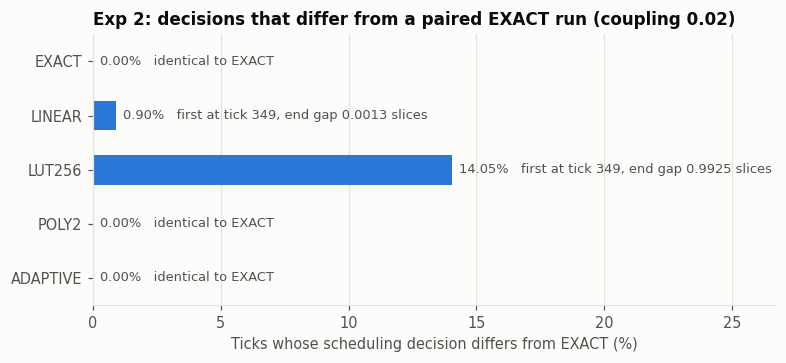

HiPrio share by mode: EXACT 48.40%, LINEAR 48.40%, LUT256 48.45%, POLY2 48.40%, ADAPTIVE 48.40%; ideal from weights alone 48.25%


In [5]:
display(exp2)

modes2 = list(exp2['Mode'])
diff2 = exp2['Decisions differ%'].to_numpy()
first2 = exp2['First divergence tick'].to_numpy()
gap2 = exp2['Max vruntime gap vs EXACT (slices)'].to_numpy()

fig, ax = plt.subplots(figsize=(8, 3.2))
y = np.arange(len(modes2))[::-1]
ax.barh(y, diff2, height=0.55, color=MODE_COLOR['LINEAR'])
ax.set_yticks(y, modes2)
ax.set_xlabel('Ticks whose scheduling decision differs from EXACT (%)')
ax.set_xlim(0, max(diff2.max() * 1.9, 1))
ax.grid(axis='y', visible=False)
for yi, d, f, g in zip(y, diff2, first2, gap2):
    label = (f'{d:.2f}%   first at tick {int(f)}, end gap {g:.4f} slices' if f >= 0
             else f'{d:.2f}%   identical to EXACT')
    ax.text(d + ax.get_xlim()[1] * 0.01, yi, label, va='center', color=INK2, fontsize=8.5)
ax.set_title(f"Exp 2: decisions that differ from a paired EXACT run (coupling {EXTRAS['exp2_load_coupling']:.2f})", loc='left')
save(fig, 'exp2_decisions_differ.png')

print(f"HiPrio share by mode: {', '.join(f'{m} {s:.2f}%' for m, s in zip(modes2, exp2['HiPrio Share%']))}; "
      f"ideal from weights alone {EXTRAS['exp2_ideal_hiprio_share_pct']:.2f}%")

## Experiment 2b: How much does Experiment 2 depend on the coupling constant?

The coupling constant is invented, so Experiment 2 is rerun at coupling 0.02, 0.2 and 1.0. If the ranking of
modes changes with this constant, Experiment 2 says more about the model than about the approximations.

,Coupling,LINEAR differ%,LUT256 differ%,POLY2 differ%,ADAPTIVE differ%
0,0.02,0.90,14.05,0.0,0.00
1,0.20,28.75,63.85,0.0,0.00
2,1.00,39.00,47.45,2.6,43.35


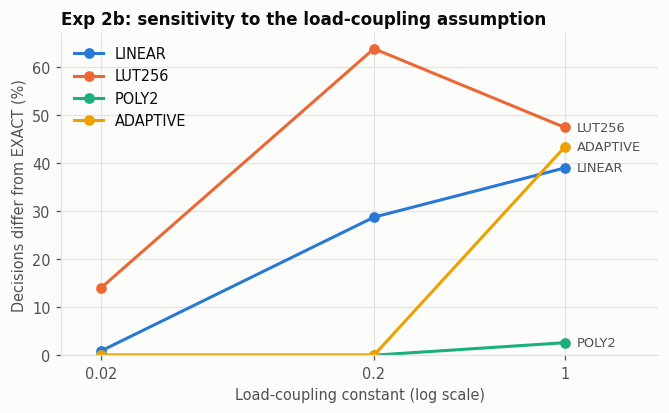

In [6]:
display(exp2b)

fig, ax = plt.subplots(figsize=(7, 3.8))
coup = exp2b['Coupling'].to_numpy()
for mode in ['LINEAR', 'LUT256', 'POLY2', 'ADAPTIVE']:
    vals = exp2b[f'{mode} differ%'].to_numpy()
    ax.plot(coup, vals, marker='o', markersize=6, linewidth=2, color=MODE_COLOR[mode], label=mode)
    ax.annotate(mode, (coup[-1], vals[-1]), xytext=(8, 0), textcoords='offset points',
                va='center', color=INK2, fontsize=8.5)
ax.set_xscale('log')
ax.set_xticks(coup, [f'{c:g}' for c in coup])
ax.minorticks_off()
ax.set_xlim(coup[0] / 1.4, coup[-1] * 2.2)
ax.set_ylim(bottom=0)
ax.set_xlabel('Load-coupling constant (log scale)')
ax.set_ylabel('Decisions differ from EXACT (%)')
ax.legend(frameon=False, loc='upper left')
ax.set_title('Exp 2b: sensitivity to the load-coupling assumption', loc='left')
save(fig, 'exp2b_coupling_sensitivity.png')

## Experiment 3: ADAPTIVE controller over a phased load

60 nice-0 tasks, 2000 ticks. Runnable tasks: 5 (ticks 0-499), 55 (500-1499), 15 (1500-1999). Vruntimes and
load averages are reset at each phase boundary. The controller samples every 8 ticks and compares a
fairness signal against `0.05 / 0.10 / 0.02 / 0.04 * w_min`.

Two caveats, both from the README's Known limitations:

- The signal used here is a *percentage* (max pairwise gap / mean vruntime) while the thresholds are in
  weight units, so the units do not match.
- The signal measures contention, not approximation error. ADAPTIVE therefore moves toward STRICT (exact
  arithmetic) when the run queue is longest, which is the opposite of saving work under load.

,Phase,Tasks,SAFE ticks,CAUTION ticks,STRICT ticks,Mean normalized gap%
0,1.0,5.0,484.0,16.0,0.0,3.36
1,2.0,55.0,4.0,8.0,988.0,555.32
2,3.0,15.0,0.0,16.0,484.0,92.55


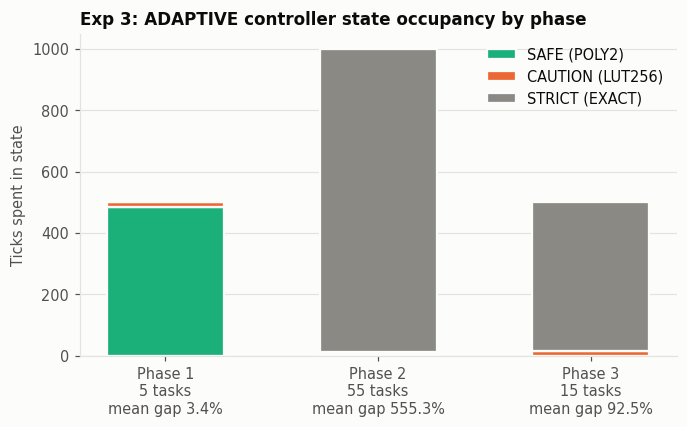

Reaction after the spike at tick 500: 4 ticks (128 ms); monitor interval 8 ticks (256 ms)
Transitions: {'SAFE->CAUTION': 2, 'CAUTION->STRICT': 1, 'STRICT->CAUTION': 1, 'CAUTION->SAFE': 1}


In [7]:
display(exp3)

phases = [f"Phase {int(p)}\n{int(t)} tasks\nmean gap {g:.1f}%"
          for p, t, g in zip(exp3['Phase'], exp3['Tasks'], exp3['Mean normalized gap%'])]
fig, ax = plt.subplots(figsize=(7, 3.8))
bottom = np.zeros(len(exp3))
for state in ['SAFE', 'CAUTION', 'STRICT']:
    vals = exp3[f'{state} ticks'].to_numpy()
    ax.bar(phases, vals, bottom=bottom, width=0.55, color=STATE_COLOR[state], edgecolor=SURFACE,
           linewidth=1.5, label=f"{state} ({ {'SAFE': 'POLY2', 'CAUTION': 'LUT256', 'STRICT': 'EXACT'}[state] })")
    bottom += vals
ax.set_ylabel('Ticks spent in state')
ax.grid(axis='x', visible=False)
ax.legend(frameon=False, loc='upper right')
ax.set_title('Exp 3: ADAPTIVE controller state occupancy by phase', loc='left')
save(fig, 'exp3_state_occupancy.png')

if EXTRAS['exp3_reaction_ticks'] is None:
    print('No controller state change after the spike at tick 500.')
else:
    print(f"Reaction after the spike at tick 500: {EXTRAS['exp3_reaction_ticks']} ticks "
          f"({EXTRAS['exp3_reaction_ms']} ms); monitor interval {EXTRAS['exp3_monitor_interval_ticks']} ticks "
          f"({EXTRAS['exp3_monitor_interval_ms']} ms)")
print('Transitions:', EXTRAS['exp3_transitions'])

## Experiment 4: Theorem 2, analytic bounds vs a shadow exact tracker

Every task carries two load averages fed the *same* inputs `c`: one updated with the mode's decay
`d~`, one with exact decay `d`. Their gap is therefore pure arithmetic error.

**Theorem 2.** Let $L_{k+1} = d_k L_k + (1-d_k)c_k$ and $\tilde L_{k+1} = \tilde d_k \tilde L_k + (1-\tilde d_k)c_k$
with $c_k \in [0,1]$, $d_k \in [0,1]$ and $L_0 = \tilde L_0 \in [0,1]$. If $|\tilde d_k - d_k| \le \delta$
and $0 \le \tilde d_k \le D < 1$ for every $k$, then
$$|\tilde L_k - L_k| \le \delta\,\frac{1-D^k}{1-D} \le \frac{\delta}{1-D}.$$

*Proof.* Let $e_k = \tilde L_k - L_k$. Subtracting the two updates,
$e_{k+1} = \tilde d_k e_k + (\tilde d_k - d_k)(L_k - c_k)$. $L_k$ is a convex combination of values in
$[0,1]$, so $L_k \in [0,1]$ and $|L_k - c_k| \le 1$. Hence $|e_{k+1}| \le D|e_k| + \delta$, and unrolling from
$e_0 = 0$ gives $|e_k| \le \delta \sum_{j<k} D^j = \delta (1-D^k)/(1-D)$. $\square$

In the simulator, $\delta$ is the per-step bound from the mode table, evaluated at the largest decay window
the run used (all three bounds grow with $t$). $D$ is the largest value the approximate decay takes on that
window range; each variant is monotone or convex there, so it is attained at an endpoint. The bound formulas
are fixed in `src/approx.c` before the run; only the window range comes from the run.

Two workloads: `mixed20` (20 tasks, nice -10..0) and `equal100` (100 nice-0 tasks), 1000 ticks each.
The figure uses a log scale; EXACT is omitted because its bound and error are both 0.

,Workload,Mode,Max window ms,Step bound,Step observed,Load bound,Load observed,Observed/Bound,Verified
0,mixed20,EXACT,169.6,0.000000,0.000000,0.00000,0.000000,NaN,YES
1,mixed20,LINEAR,169.6,0.006907,0.006644,0.31150,0.001514,0.005,YES
2,mixed20,LUT256,169.6,0.011140,0.010680,0.50860,0.023760,0.047,YES
3,mixed20,POLY2,169.6,0.000271,0.000263,0.01234,0.000017,0.001,YES
4,mixed20,ADAPTIVE,169.6,0.011140,0.000263,0.50860,0.000017,0.000,YES
5,equal100,EXACT,289.6,0.000000,0.000000,0.00000,0.000000,NaN,YES
6,equal100,LINEAR,286.4,0.019700,0.018460,0.88820,0.001007,0.001,YES
7,equal100,LUT256,288.0,0.011140,0.010680,0.50860,0.006473,0.013,YES
8,equal100,POLY2,289.6,0.001347,0.001282,0.06143,0.000016,0.000,YES
9,equal100,ADAPTIVE,289.6,0.011140,0.001282,0.50860,0.000016,0.000,YES


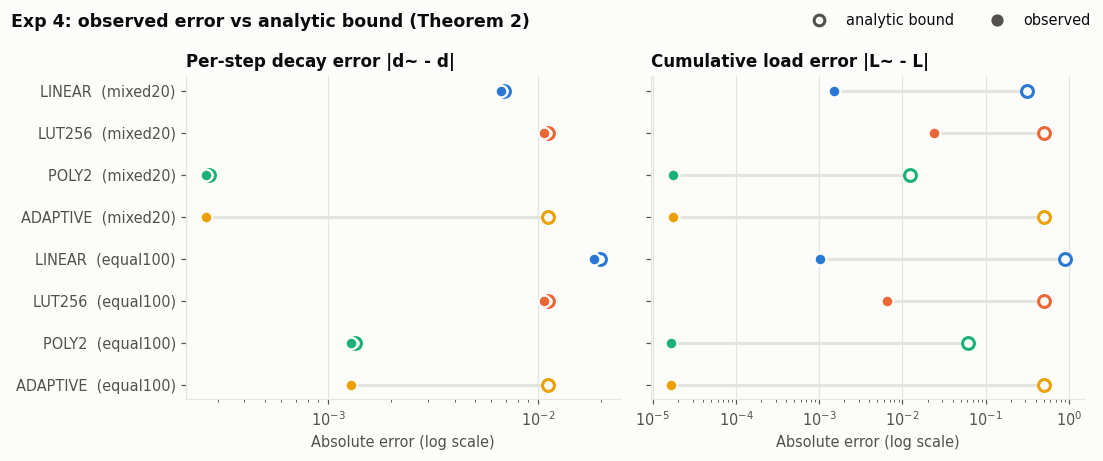

Fixed modes, observed/bound per step: 93.7% to 97.1%
Fixed modes, observed/bound cumulative: 0.03% to 4.67%
mixed20: ADAPTIVE observed errors equal POLY2's (consistent with the controller staying in SAFE)
equal100: ADAPTIVE observed errors equal POLY2's (consistent with the controller staying in SAFE)


In [8]:
display(exp4)
assert (exp4['Verified'] == 'YES').all(), 'an analytic bound was violated'

e4 = exp4[exp4['Mode'] != 'EXACT'].reset_index(drop=True)
labels = [f"{m}  ({w})" for w, m in zip(e4['Workload'], e4['Mode'])]
y = np.arange(len(e4))[::-1]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for ax, kind, title in [(axes[0], 'Step', 'Per-step decay error |d~ - d|'),
                        (axes[1], 'Load', 'Cumulative load error |L~ - L|')]:
    bound, obs = e4[f'{kind} bound'].to_numpy(), e4[f'{kind} observed'].to_numpy()
    for yi, b, o, m in zip(y, bound, obs, e4['Mode']):
        c = MODE_COLOR[m]
        ax.plot([o, b], [yi, yi], color=GRID, linewidth=2, zorder=1)
        ax.scatter(b, yi, s=60, facecolor=SURFACE, edgecolor=c, linewidth=2, zorder=3)
        ax.scatter(o, yi, s=60, color=c, edgecolor=SURFACE, linewidth=1.5, zorder=4)
    ax.set_xscale('log')
    ax.set_title(title, loc='left')
    ax.set_xlabel('Absolute error (log scale)')
    ax.grid(axis='y', visible=False)
axes[0].set_yticks(y, labels)
handles = [plt.Line2D([], [], marker='o', linestyle='', markersize=7, markerfacecolor=SURFACE,
                      markeredgecolor=INK2, markeredgewidth=2, label='analytic bound'),
           plt.Line2D([], [], marker='o', linestyle='', markersize=7, color=INK2, label='observed')]
fig.suptitle('Exp 4: observed error vs analytic bound (Theorem 2)', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
fig.legend(handles=handles, frameon=False, loc='upper right', ncol=2)
save(fig, 'exp4_bounds_vs_observed.png')

fixed = exp4[exp4['Mode'].isin(['LINEAR', 'LUT256', 'POLY2'])]
step_ratio = fixed['Step observed'] / fixed['Step bound']
load_ratio = fixed['Load observed'] / fixed['Load bound']
print(f'Fixed modes, observed/bound per step: {step_ratio.min():.1%} to {step_ratio.max():.1%}')
print(f'Fixed modes, observed/bound cumulative: {load_ratio.min():.2%} to {load_ratio.max():.2%}')
for w in exp4['Workload'].unique():
    sub = exp4[exp4['Workload'] == w].set_index('Mode')
    same = (sub.loc['ADAPTIVE', 'Step observed'] == sub.loc['POLY2', 'Step observed']
            and sub.loc['ADAPTIVE', 'Load observed'] == sub.loc['POLY2', 'Load observed'])
    print(f"{w}: ADAPTIVE observed errors {'equal' if same else 'differ from'} POLY2's"
          f"{' (consistent with the controller staying in SAFE)' if same else ''}")

## Experiments 5 and 6: measured cost

Both experiments time each function through a volatile function pointer over a fixed input array
(median of 21 trials). A call-only function (`return x`) is timed the same way and subtracted to give
**net ns/op**. Caveats, from the README:

- This is a throughput-style microbenchmark on one machine. It does not measure latency, does not use cycle
  counters, and has not been run on x86.
- Functions cheaper than a call are below what this method resolves; the simulator prints `n/a` for
  their speedup, and their net cost can come out slightly negative.
- The decay variants are floating point. Linux PELT already uses an integer table, so EXACT here is not the
  kernel's cost. The cube root here is not the kernel's `cubic_root()`, which runs about once per congestion
  epoch rather than per ACK.

A single run is noisy at this scale, so Experiments 5 and 6 are run again several times. In the figure,
bars are the **median** net ns/op over all runs (the main run plus the extra runs) and whiskers span the
minimum and maximum. The printed tables are the main run only. Note that the simulator prints a speedup
whenever a net cost exceeds 0.05 ns, which is inside the run-to-run spread, so a speedup printed for LINEAR or
LUT256 in a single run is not meaningful.

,Metric,LUT+NR,LUT-only,Notes
0,ns/op,1.170000,0.8800,measured; call-only baseline 0.87 ns
1,Net ns/op,0.300000,0.0100,baseline subtracted
2,Speedup (net),NaN,NaN,LUT-only below timer resolution
3,Mean error vs cbrt()%,0.000045,NaN,LUT+NR is itself approximate
4,Max error vs cbrt()%,0.000159,NaN,NaN
5,Mean error vs LUT+NR%,NaN,0.0582,cost of dropping the NR step
6,Max error vs LUT+NR%,NaN,0.1260,NaN


,Variant,ns/op,Net ns/op,Speedup vs EXACT,Max abs error
0,EXACT,2.64,1.77,1.00,0.000000
1,LINEAR,0.87,0.00,NaN,0.008334
2,LUT256,0.89,0.02,NaN,0.010680
3,POLY2,1.16,0.29,6.18,0.000371


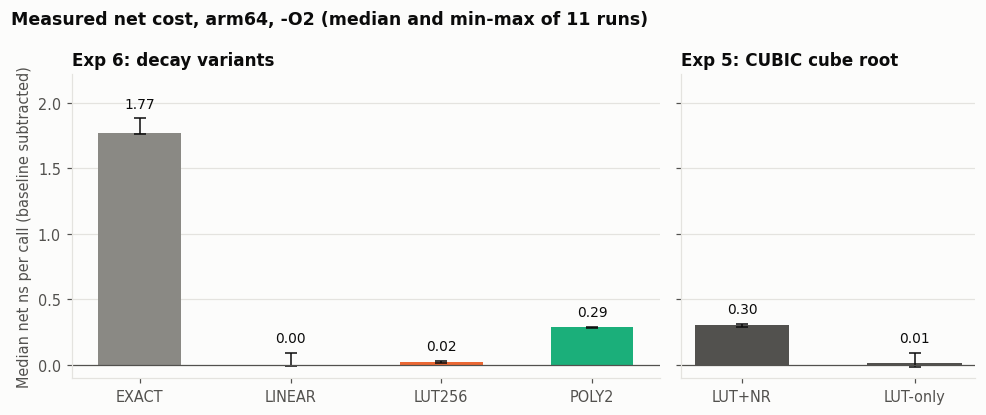

Net ns/op over 11 runs:


,median,min,max
EXACT,1.77,1.76,1.88
LINEAR,0.00,-0.01,0.09
LUT256,0.02,0.01,0.03
POLY2,0.29,0.28,0.29
LUT+NR,0.30,0.29,0.31
LUT-only,0.01,-0.02,0.09


In [9]:
display(exp5)
display(exp6)

net6_main = exp6.set_index('Variant')['Net ns/op']
net5_main = exp5.set_index('Metric').loc['Net ns/op', ['LUT+NR', 'LUT-only']].astype(float)
rep6, rep5 = [net6_main], [net5_main]
for _ in range(N_TIMING_REPEATS):
    t6, _n = parse_sections(run(['./apex_sim', '--experiment', '6']).stdout)
    t5, _n = parse_sections(run(['./apex_sim', '--experiment', '5']).stdout)
    rep6.append(section(t6, 'Experiment 6').set_index('Variant')['Net ns/op'])
    rep5.append(section(t5, 'Experiment 5').set_index('Metric').loc['Net ns/op', ['LUT+NR', 'LUT-only']])
rep6, rep5 = pd.DataFrame(rep6).reset_index(drop=True), pd.DataFrame(rep5).reset_index(drop=True)
N_TIMING_RUNS = len(rep6)  # main run + extra runs
net6, net5 = rep6.median(), rep5.median()

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True, gridspec_kw={'width_ratios': [4, 2]})
for ax, net, rep, colors, title in [
        (axes[0], net6, rep6, [MODE_COLOR[v] for v in net6.index], 'Exp 6: decay variants'),
        (axes[1], net5, rep5, [INK2, INK2], 'Exp 5: CUBIC cube root')]:
    x = np.arange(len(net))
    ax.bar(x, net.to_numpy(), width=0.55, color=colors)
    lo = (net - rep.min()).to_numpy()
    hi = (rep.max() - net).to_numpy()
    ax.errorbar(x, net.to_numpy(), yerr=[lo, hi], fmt='none', ecolor=INK, elinewidth=1, capsize=4)
    for xi, v, top in zip(x, net.to_numpy(), rep.max().to_numpy()):
        ax.text(xi, max(v, top, 0) + 0.06, f'{v:.2f}', ha='center', va='bottom', color=INK, fontsize=9)
    ax.axhline(0, color=INK2, linewidth=0.8)
    ax.set_ylim(top=max(rep6.max().max(), rep5.max().max()) * 1.18)
    ax.set_xticks(x, list(net.index))
    ax.grid(axis='x', visible=False)
    ax.set_title(title, loc='left')
axes[0].set_ylabel('Median net ns per call (baseline subtracted)')
fig.suptitle(f'Measured net cost, {RUN_INFO["machine"]}, -O2 (median and min-max of {N_TIMING_RUNS} runs)',
             x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
save(fig, 'exp5_6_net_ns.png')

print(f'Net ns/op over {N_TIMING_RUNS} runs:')
display(pd.concat({'median': pd.concat([net6, net5]), 'min': pd.concat([rep6.min(), rep5.min()]),
                   'max': pd.concat([rep6.max(), rep5.max()])}, axis=1))

## Findings from this run

The cell below states the findings in words, computed from the parsed tables, so the text cannot
drift from the numbers.

In [10]:
d2 = exp2.set_index('Mode')['Decisions differ%']
b2 = exp2b.set_index('Coupling')
e3 = exp3.set_index('Phase')
heaviest = int(exp3.loc[exp3['Tasks'].idxmax(), 'Phase'])
FINDINGS = {
    'exp1': (f"Equal weights: no starvation in any mode; the max vruntime gap differs across modes by "
             f"{gap.max() - gap.min():.4f} vruntime units (one nice-0 tick = 32)."),
    'exp2': (f"Mixed weights at coupling {EXTRAS['exp2_load_coupling']:.2f}: decisions differ from EXACT on "
             + ', '.join(f'{m} {d2[m]:.2f}%' for m in ['LINEAR', 'LUT256', 'POLY2', 'ADAPTIVE'])
             + ' of ticks. HiPrio share stays within '
             f"{(exp2['HiPrio Share%'] - EXTRAS['exp2_ideal_hiprio_share_pct']).abs().max():.2f} points of the "
             'weight-only ideal in every mode.'),
    'exp2b': ('Coupling sensitivity: ' + '; '.join(
        f"at {c:.2f}, " + ', '.join(f"{m} {b2.loc[c, f'{m} differ%']:.2f}%" for m in ['LINEAR', 'LUT256', 'POLY2', 'ADAPTIVE'])
        for c in b2.index) + '. The conclusions of Exp 2 depend on this invented constant.'),
    'exp3': (f"Controller: STRICT occupies {int(e3.loc[heaviest, 'STRICT ticks'])} of "
             f"{int(e3.loc[heaviest, ['SAFE ticks', 'CAUTION ticks', 'STRICT ticks']].sum())} ticks in phase "
             f"{heaviest}, the phase with the most runnable tasks; the signal tracks contention, not approximation error."),
    'exp4': (f"All {len(exp4)} bound checks hold. Fixed modes reach {step_ratio.min():.0%}-{step_ratio.max():.0%} of "
             f"the per-step bound (tight) and {load_ratio.min():.2%}-{load_ratio.max():.2%} of the cumulative bound (loose). "
             'Largest per-step error by workload: ' + '; '.join(
                 f"{w} {g.loc[g['Step observed'].idxmax(), 'Mode']} ({g['Step observed'].max():.3e})"
                 for w, g in fixed.groupby('Workload', sort=False)) + '.'),
    'exp5': (f"CUBIC, median of {N_TIMING_RUNS} runs: LUT+NR net {net5['LUT+NR']:.2f} ns/op "
             f"(range {rep5['LUT+NR'].min():.2f} to {rep5['LUT+NR'].max():.2f}), LUT-only net {net5['LUT-only']:.2f} ns/op "
             f"(range {rep5['LUT-only'].min():.2f} to {rep5['LUT-only'].max():.2f}); "
             f"dropping the Newton step costs mean "
             f"{exp5.set_index('Metric').loc['Mean error vs LUT+NR%', 'LUT-only']:.4f}% relative error."),
    'exp6': (f'Decay net ns/op, median of {N_TIMING_RUNS} runs (range): '
             + ', '.join(f'{v} {net6[v]:.2f} ({rep6[v].min():.2f} to {rep6[v].max():.2f})' for v in net6.index)
             + '. Medians within a few hundredths of a ns of zero are below what this benchmark resolves.'),
}
for k, v in FINDINGS.items():
    print(f'[{k}] {v}\n')

[exp1] Equal weights: no starvation in any mode; the max vruntime gap differs across modes by 0.0003 vruntime units (one nice-0 tick = 32).

[exp2] Mixed weights at coupling 0.02: decisions differ from EXACT on LINEAR 0.90%, LUT256 14.05%, POLY2 0.00%, ADAPTIVE 0.00% of ticks. HiPrio share stays within 0.20 points of the weight-only ideal in every mode.

[exp2b] Coupling sensitivity: at 0.02, LINEAR 0.90%, LUT256 14.05%, POLY2 0.00%, ADAPTIVE 0.00%; at 0.20, LINEAR 28.75%, LUT256 63.85%, POLY2 0.00%, ADAPTIVE 0.00%; at 1.00, LINEAR 39.00%, LUT256 47.45%, POLY2 2.60%, ADAPTIVE 43.35%. The conclusions of Exp 2 depend on this invented constant.

[exp3] Controller: STRICT occupies 988 of 1000 ticks in phase 2, the phase with the most runnable tasks; the signal tracks contention, not approximation error.

[exp4] All 10 bound checks hold. Fixed modes reach 94%-97% of the per-step bound (tight) and 0.03%-4.67% of the cumulative bound (loose). Largest per-step error by workload: mixed20 LUT256

## Known limitations

Copied from the README; they bound what the results above can claim.

- **Load coupling is invented.** Effective weight is `weight * (1 + 0.02 * (load_avg - 0.5))`. Real CFS does
  not feed PELT into vruntime; PELT matters for load balancing and frequency selection (schedutil / EAS).
  Experiment 2b shows the conclusions depend heavily on this constant.
- **Controller signal and units.** Thresholds scaled by `w_min` are compared against vruntime gaps or, in
  Experiment 3, a percentage. The signal reflects contention, not approximation error, so ADAPTIVE goes to
  STRICT exactly when the load is heaviest.
- **Floating point, not kernel fixed point.** Linux PELT already uses an integer table
  (`runnable_avg_yN_inv`, `y^32 = 1/2`, 1024 us periods). The CUBIC routine here is not the kernel's
  `cubic_root()`, which runs about once per congestion epoch.
- **Throughput-style microbenchmark** through a function pointer. Functions cheaper than a call are
  reported as `n/a`. It does not yet measure latency, use cycle counters, or run on x86.
- **Synthetic, deterministic workloads.** There is no randomness, so there are no seeds or confidence
  intervals yet.

## Export

Everything above is written to `apex_notebook_outputs/apex_results.json`, together with the raw simulator
output and the build and machine details of this run.

In [11]:
def records(df):
    return json.loads(df.to_json(orient='records'))  # NaN -> null


results = {
    'run_info': RUN_INFO,
    'command': './apex_sim --experiment all',
    'raw_output_file': 'apex_notebook_outputs/simulator_output.txt',
    'tables': {name: records(df) for name, df in tables.items()},
    'extras': EXTRAS,
    'timing_repeats': {
        'n_runs': N_TIMING_RUNS,
        'note': 'index 0 is the main run (same as tables); the rest are extra runs of --experiment 5 and 6',
        'exp6_net_ns_per_op': {k: [float(v) for v in rep6[k]] for k in rep6.columns},
        'exp5_net_ns_per_op': {k: [float(v) for v in rep5[k]] for k in rep5.columns},
    },
    'findings': FINDINGS,
    'figures': FIGURES,
    'raw_output': RAW,
}
out_path = OUT / 'apex_results.json'
out_path.write_text(json.dumps(results, indent=2), encoding='utf-8')
print(f'Wrote {out_path.relative_to(ROOT)}')
print('Figures:', *FIGURES, sep='\n  ')

Wrote apex_notebook_outputs/apex_results.json
Figures:
  apex_notebook_outputs/exp2_decisions_differ.png
  apex_notebook_outputs/exp2b_coupling_sensitivity.png
  apex_notebook_outputs/exp3_state_occupancy.png
  apex_notebook_outputs/exp4_bounds_vs_observed.png
  apex_notebook_outputs/exp5_6_net_ns.png
